# DS3000 Project Phase II: What Gives a UFC Fighter the Edge?

**Group members:** Kyle Johnson, Chris Mazzeo, Kevin Le

**Contributions:** Kyle: project idea, data pipeline, and integration (Parts 1–2). Chris: visualizations (Part 3). Kevin: model-checking functions (Part 4). Everyone: ethics discussion (Part 5).

**Data source:** API-MMA from API-Sports (https://api-sports.io/sports/mma), collected in Python with `requests`. The API returns JSON.

## Part 1: Motivation, Questions, and Pipeline Summary

### The problem

Mixed martial arts has grown from a fringe sport into one of the most valuable properties in sports. In August 2025, Paramount agreed to pay about \$7.7 billion over seven years (around $1.1 billion per year) for the exclusive U.S. rights to UFC events, starting in 2026 [1]. With that much money and attention on the sport, matchmakers, coaches, commentators, fans, and sports bettors all want to understand what makes a fighter successful.

Fight commentary is full of conventional wisdom about a fighter's body. Commentators constantly point to reach (arm span) as an advantage, describe southpaw (left-leading) fighters as awkward to face, and say that bigger fighters in heavier divisions are more likely to win by knockout. Some of these ideas have been tested: Richardson and Gilman [2] studied more than 13,800 professional boxers and MMA fighters and found that left-handed fighters win more often, likely because opponents rarely get to practice against them. Other common beliefs are rarely checked against data.

For me, I've been an amateur boxer for many years of my life, and have always followed the UFC. I spend most of my Saturdays watching the entire card and have trained with multiple UFC fighters that have came to my gym to work on their striking.

### Questions of interest

1. **Do physical traits give fighters an edge?** Do fighters with a longer reach than is typical for their weight class, or who fight southpaw, have better win records?

2. **Does a fighter's body shape *how* they win?** Can we predict whether a fighter wins mostly by **knockout**, **submission**, or **decision** (the judges' scorecards) from their height, reach, weight class, and stance?

### Data processing pipeline (summary)

Data comes from **API-MMA** (API-Sports, `https://v1.mma.api-sports.io/`), which returns JSON. The free plan allows 100 requests per key per day, so every API response is saved to a file and the API is never asked for the same thing twice. The pipeline has five steps:

1. **Weight classes** (`/categories`, 1 request): returns 18 category names, including non-standard ones like "Catch Weight" and "Open Weight".
2. **Fighter profiles** (`/fighters?category=...`, 1 request per category, 18 total): returns 2,536 fighter entries with name, gender, height, weight, reach, stance, and weight class. Saved to `fighters_raw.json`.
3. **Cleaning the profiles:** height (`5' 9'`), reach (`71'`), and weight (`136 lbs`) arrive as text and are converted to numbers in inches and pounds. Entries under non-standard categories are removed, and each fighter is kept once under their standard weight class (2,455 fighters). Fighters missing height, reach, or stance are excluded from sampling, leaving 1,672 fighters.
4. **Fighter records** (`/fighters/records?id=...`, 1 request per fighter): the 1,672 fighters are shuffled with a fixed `random_state`, and the first 225 are split into three batches of 75. Each group member downloaded one batch with their own API key (`records_batch1.json`, `records_batch2.json`, `records_batch3.json`). Each record gives total wins, losses, and draws, plus wins by KO and by submission.
5. **Merging, feature engineering, and quality checks:** the three batches are combined and joined to the profiles on fighter `id`. Fighters with no record data in the API are dropped (58 of the 225), along with rows that fail sanity checks. Derived columns: `decision_wins` (wins − KO wins − submission wins), `total_fights`, `win_pct` (wins ÷ (wins + losses)), `win_style` (the most common way the fighter wins), and `reach_vs_class` (reach minus the median reach of the fighter's weight class). The result is saved to `ufc_fighters_clean.csv`.

### Sources

[1] NBC News (August 2025). "Paramount buys UFC rights in $7.7 billion deal." https://www.nbcnews.com/business/media/paramount-buys-ufc-rights-seven-years-rcna224261

[2] Richardson, T., & Gilman, R. T. (2019). Left-handedness is associated with greater fighting success in humans. *Scientific Reports*, 9, 15402. https://pmc.ncbi.nlm.nih.gov/articles/PMC6817864

[3] API-Sports, API-MMA documentation. https://api-sports.io/documentation/mma/v1

## Part 2: Obtaining, Cleaning, and Merging the Data

**To run this notebook:** put `fighters_raw.json`, `records_batch1.json`, `records_batch2.json`, and `records_batch3.json` (all in our GitHub repo) in the same folder as this notebook. The code loads the saved API responses from these files, so **no API key is needed** and the results are the same every time. The API is only called (and a key requested) if one of those files is missing.

### 2.1 Setup

In [1]:
import os
import json
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from getpass import getpass

BASE_URL = "https://v1.mma.api-sports.io/"
BATCH_SIZE = 75     # fighters per group member
API_KEY = None      # only asked for if the API actually needs to be called


def get(endpoint, params=None):
    """Call the API and return the JSON response as a Python dictionary."""
    global API_KEY
    if API_KEY is None:
        API_KEY = getpass("Paste your API key and press Enter: ").strip()
    response = requests.get(BASE_URL + endpoint, headers={"x-apisports-key": API_KEY}, params=params)
    data = response.json()
    if data.get("errors"):
        raise Exception(f"API error: {data['errors']}")
    return data

### 2.2 Fighter profiles

Loads `fighters_raw.json` if it's in the folder. Otherwise downloads every fighter in every weight class (19 requests).

In [2]:
if os.path.exists("fighters_raw.json"):
    with open("fighters_raw.json") as f:
        fighters_raw = json.load(f)
    print("Loaded fighters from file.")
else:
    categories = get("categories")["response"]
    fighters_raw = []
    for category in categories:
        data = get("fighters", {"category": category})
        fighters_raw.extend(data["response"])
        print(category, ":", len(data["response"]), "fighters")
        time.sleep(7)  # free plan allows about 10 requests per minute
    with open("fighters_raw.json", "w") as f:
        json.dump(fighters_raw, f)

print("Total fighter entries:", len(fighters_raw))
print()
print("One fighter as returned by the API:")
print(json.dumps(fighters_raw[0], indent=2))

Loaded fighters from file.
Total fighter entries: 2536

One fighter as returned by the API:
{
  "id": 745,
  "name": "Aaron Phillips",
  "nickname": "The Dragon",
  "photo": "https://media.api-sports.io/mma/fighters/745.png",
  "gender": "M",
  "birth_date": null,
  "age": null,
  "height": "5' 9'",
  "weight": "136 lbs",
  "reach": "71'",
  "stance": "Southpaw",
  "category": "Bantamweight",
  "team": {
    "id": 329,
    "name": "Headkicks MMA"
  },
  "last_update": "2025-06-04T19:23:06+00:00"
}


### 2.3 Clean the fighter profiles

* Convert height, reach, and weight from text to numbers. The API marks inches with a single quote (`5' 9'`, `71'`).
* Remove non-standard weight categories. A fighter can be listed under both "Catch Weight" and their real division, and catchweight bouts don't tell us which division a fighter belongs to. Women's Lightweight and Super Heavyweight are also removed because they have only 1–2 fighters.
* Keep each fighter once.

In [3]:
def height_to_inches(text):
    """Convert a height like 5' 9' or 5' 9" to inches (5 * 12 + 9 = 69)."""
    if not text:
        return None
    parts = str(text).replace("'", " ").replace('"', " ").split()
    try:
        if len(parts) == 2:
            return int(parts[0]) * 12 + float(parts[1])
        if len(parts) == 1:
            return int(parts[0]) * 12
    except ValueError:
        return None
    return None


def text_to_number(text):
    """Convert text like 71' or 136 lbs to a plain number (71.0 or 136.0)."""
    if not text:
        return None
    text = str(text).replace("'", " ").replace('"', " ")
    try:
        return float(text.split()[0])
    except (ValueError, IndexError):
        return None


NON_STANDARD = ["Catch Weight", "Catchweight", "Open Weight", "Super Heavyweight",
                "Women's Catch Weight", "Women's Lightweight"]

rows = []
for f in fighters_raw:
    if f.get("category") in NON_STANDARD:
        continue
    rows.append({
        "id": f.get("id"),
        "name": f.get("name"),
        "gender": f.get("gender"),
        "weight_class": f.get("category"),
        "stance": f.get("stance"),
        "height_in": height_to_inches(f.get("height")),
        "weight_lbs": text_to_number(f.get("weight")),
        "reach_in": text_to_number(f.get("reach")),
    })

fighters = pd.DataFrame(rows).drop_duplicates("id")
print("Fighters after cleaning:", len(fighters))
print("Missing values:")
print(fighters.isna().sum())
fighters.head()

Fighters after cleaning: 2455
Missing values:
id                0
name              0
gender            0
weight_class      0
stance           74
height_in       702
weight_lbs      702
reach_in        369
dtype: int64


,id,name,gender,weight_class,stance,height_in,weight_lbs,reach_in
0,745,Aaron Phillips,M,Bantamweight,Southpaw,69.0,136.0,71.0
1,769,Adrian Yanez,M,Bantamweight,Orthodox,67.0,136.0,70.0
2,283,Aiemann Zahabi,M,Bantamweight,Orthodox,68.0,142.0,68.5
3,2683,AJ Cunningham,M,Bantamweight,Orthodox,70.0,136.0,71.0
4,584,Alatengheili,M,Bantamweight,Orthodox,65.0,136.0,66.0


### 2.4 Fighter records (three batches)

Everyone in the group used the **same** shuffled list of fighters (fixed `random_state`), and each person downloaded one slice of 75 with their own API key: batch 1 = fighters 1–75 (Kyle), batch 2 = 76–150, batch 3 = 151–225. This cell loads each batch file and only calls the API for fighters that are missing, so with all three files present it makes no requests.

In [4]:
known = fighters.dropna(subset=["height_in", "reach_in", "stance"])
shuffled = known.sample(frac=1, random_state=3000)   # same order for everyone
print("Fighters with full physical data:", len(known))

for batch in [1, 2, 3]:
    start = (batch - 1) * BATCH_SIZE
    batch_fighters = shuffled.iloc[start : start + BATCH_SIZE]
    batch_file = f"records_batch{batch}.json"

    if os.path.exists(batch_file):
        with open(batch_file) as f:
            batch_records = json.load(f)
    else:
        batch_records = {}

    for fighter_id in batch_fighters["id"]:
        if str(fighter_id) in batch_records:
            continue  # already downloaded
        data = get("fighters/records", {"id": fighter_id})
        if data["response"]:
            batch_records[str(fighter_id)] = data["response"][0]
        with open(batch_file, "w") as f:
            json.dump(batch_records, f)
        time.sleep(7)

    print(f"{batch_file}: {len(batch_records)} records (fighters {start + 1} to {start + len(batch_fighters)})")

Fighters with full physical data: 1672
records_batch1.json: 75 records (fighters 1 to 75)
records_batch2.json: 75 records (fighters 76 to 150)
records_batch3.json: 75 records (fighters 151 to 225)


### 2.5 Merge the batches with the fighter profiles

The three batch files are combined (duplicates counted once) and joined to the cleaned profiles on fighter `id`. For some fighters the API returns a record with every value empty (`null`); these fighters are reported and dropped.

In [5]:
all_records = {}
for batch in [1, 2, 3]:
    with open(f"records_batch{batch}.json") as f:
        all_records.update(json.load(f))

print("One record as returned by the API:")
print(json.dumps(next(iter(all_records.values())), indent=2))
print()

record_rows = []
for fighter_id, r in all_records.items():
    record_rows.append({
        "id": int(fighter_id),
        "wins": r["total"]["win"],
        "losses": r["total"]["loss"],
        "draws": r["total"]["draw"],
        "ko_wins": r["ko"]["win"],
        "sub_wins": r["sub"]["win"],
    })
records = pd.DataFrame(record_rows)

missing = records["wins"].isna().sum()
print("Fighters with records downloaded:", len(records))
print("Fighters with no record data in the API (dropped):", missing)
records = records.dropna(subset=["wins", "losses"])

df = fighters.merge(records, on="id", how="inner")
print("Rows after merging profiles with records:", len(df))

One record as returned by the API:
{
  "fighter": {
    "id": 2664,
    "name": "Tom Nolan",
    "photo": "https://media.api-sports.io/mma/fighters/2664.png"
  },
  "total": {
    "win": null,
    "loss": null,
    "draw": null
  },
  "ko": {
    "win": null,
    "loss": null
  },
  "sub": {
    "win": null,
    "loss": null
  }
}

Fighters with records downloaded: 225
Fighters with no record data in the API (dropped): 58
Rows after merging profiles with records: 167


### 2.6 Feature engineering and quality checks

In [6]:
df["decision_wins"] = df["wins"] - df["ko_wins"] - df["sub_wins"]
df["total_fights"] = df["wins"] + df["losses"] + df["draws"]
df["win_pct"] = df["wins"] / (df["wins"] + df["losses"])


def win_style(row):
    if row["ko_wins"] >= row["sub_wins"] and row["ko_wins"] >= row["decision_wins"]:
        return "KO"
    elif row["sub_wins"] >= row["decision_wins"]:
        return "Submission"
    else:
        return "Decision"


df["win_style"] = df.apply(win_style, axis=1)
df["reach_vs_class"] = df["reach_in"] - df.groupby("weight_class")["reach_in"].transform("median")

# Quality checks: remove rows that can't be right
before = len(df)
df = df[df["total_fights"] > 0]                  # no fights recorded
df = df[df["decision_wins"] >= 0]                # KO + sub wins can't exceed total wins
df = df[df["height_in"].between(58, 84)]         # 4'10" to 7'0"
df = df[df["reach_in"].between(55, 90)]          # realistic arm spans
print(f"Removed {before - len(df)} rows that failed quality checks")

df = df.reset_index(drop=True)
df.to_csv("ufc_fighters_clean.csv", index=False)
print("Final data set:", df.shape)
df.head(10)

Removed 0 rows that failed quality checks
Final data set: (167, 18)


,id,name,gender,weight_class,stance,height_in,weight_lbs,reach_in,wins,losses,draws,ko_wins,sub_wins,decision_wins,total_fights,win_pct,win_style,reach_vs_class
0,2683,AJ Cunningham,M,Bantamweight,Orthodox,70.0,136.0,71.0,11.0,5.0,0.0,4.0,4.0,3.0,16.0,0.687500,KO,1.0
1,1404,Albert Morales,M,Bantamweight,Orthodox,69.0,135.0,72.0,7.0,6.0,1.0,2.0,3.0,2.0,14.0,0.538462,Submission,2.0
2,2669,Angel Pacheco,M,Bantamweight,Orthodox,68.0,135.0,70.0,7.0,4.0,0.0,5.0,2.0,0.0,11.0,0.636364,KO,0.0
3,2721,Baergeng Jieleyisi,M,Bantamweight,Orthodox,69.0,135.0,70.0,18.0,6.0,0.0,4.0,10.0,4.0,24.0,0.750000,Submission,0.0
4,2296,Bharat Kandare,M,Bantamweight,Orthodox,67.0,145.0,72.0,5.0,3.0,0.0,2.0,3.0,0.0,8.0,0.625000,Submission,2.0
5,280,Brian Kelleher,M,Bantamweight,Switch,66.0,136.0,66.0,24.0,16.0,0.0,8.0,10.0,6.0,40.0,0.600000,Submission,-4.0
6,1312,Bryan Caraway,M,Bantamweight,Orthodox,68.0,135.0,68.0,21.0,10.0,0.0,2.0,16.0,3.0,31.0,0.677419,Submission,-2.0
7,2536,CaolÃ¡n Loughran,M,Bantamweight,Orthodox,66.0,136.0,68.0,10.0,2.0,0.0,5.0,2.0,3.0,12.0,0.833333,KO,-2.0
8,2670,Charalampos Grigoriou,M,Bantamweight,Orthodox,67.0,136.0,67.5,8.0,5.0,0.0,6.0,0.0,2.0,13.0,0.615385,KO,-2.5
9,2474,Cristian QuiÃ±onez,M,Bantamweight,Orthodox,68.0,136.0,70.0,19.0,5.0,0.0,10.0,3.0,6.0,24.0,0.791667,KO,0.0


### 2.7 A first look at the cleaned data

In [7]:
print("Fighters per weight class:")
print(df["weight_class"].value_counts())
print()
print("Fighters per stance:")
print(df["stance"].value_counts())
print()
print("Main way of winning:")
print(df["win_style"].value_counts())
print()
print("Gender:")
print(df["gender"].value_counts())

Fighters per weight class:
weight_class
Lightweight              28
Welterweight             24
Bantamweight             23
Middleweight             19
Featherweight            15
Heavyweight              15
Light Heavyweight        10
Women's Strawweight       9
Flyweight                 8
Women's Bantamweight      8
Women's Flyweight         7
Women's Featherweight     1
Name: count, dtype: int64

Fighters per stance:
stance
Orthodox    127
Southpaw     23
Switch       17
Name: count, dtype: int64

Main way of winning:
win_style
KO            72
Submission    50
Decision      45
Name: count, dtype: int64

Gender:
gender
M    142
W     25
Name: count, dtype: int64


In [8]:
df[["height_in", "reach_in", "reach_vs_class", "wins", "losses", "total_fights", "win_pct"]].describe().round(2)

,height_in,reach_in,reach_vs_class,wins,losses,total_fights,win_pct
count,167.00,167.00,167.00,167.00,167.00,167.00,167.00
mean,69.76,71.49,-0.03,13.75,5.83,19.77,0.71
std,3.56,4.05,2.04,7.24,3.93,10.58,0.10
min,60.00,60.00,-7.50,1.00,0.00,3.00,0.33
25%,67.00,68.50,-1.50,8.00,3.00,12.00,0.65
50%,70.00,72.00,0.00,12.00,5.00,17.00,0.71
75%,72.00,75.00,1.00,17.00,7.00,25.00,0.76
max,78.00,80.00,5.00,38.00,23.00,57.00,1.00


## Part 3: Visualizations

### Visualization 1: Reach advantage vs. win %, by stance (Question 1)

Each dot is one fighter with at least 5 pro fights. The x-axis shows how much longer (positive) or shorter (negative) the fighter's reach is than the median reach in their weight class, and the y-axis shows their win percentage. Dots are colored by stance, so one chart covers both parts of Question 1: whether reach advantage and stance relate to winning. The dashed line is the trend for all fighters, and its slope is shown in the legend.

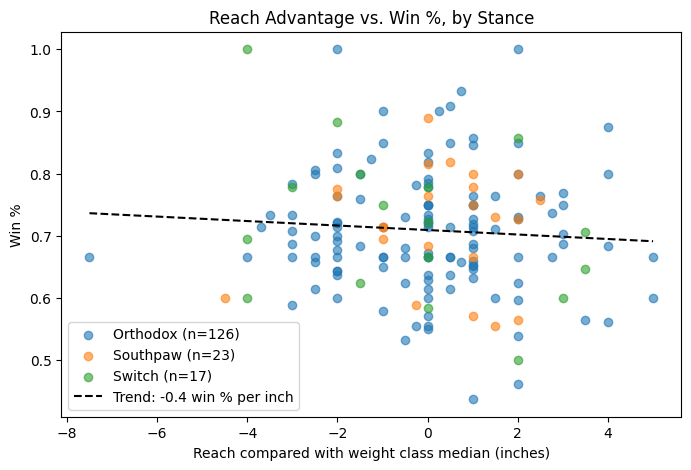

In [9]:
d = df[df["total_fights"] >= 5].dropna(subset=["reach_vs_class", "win_pct"])

fig, ax = plt.subplots(figsize=(8, 5))

# one color per stance, so this chart covers both parts of Question 1
for stance, group in d.groupby("stance"):
    ax.scatter(group["reach_vs_class"], group["win_pct"], alpha=0.6, label=f"{stance} (n={len(group)})")

# trend line for all fighters
m, b = np.polyfit(d["reach_vs_class"], d["win_pct"], 1)
x = np.linspace(d["reach_vs_class"].min(), d["reach_vs_class"].max(), 100)
ax.plot(x, m * x + b, color="black", linestyle="--", label=f"Trend: {m * 100:+.1f} win % per inch")

ax.set_title("Reach Advantage vs. Win %, by Stance")
ax.set_xlabel("Reach compared with weight class median (inches)")
ax.set_ylabel("Win %")
ax.legend()
plt.show()

**What it shows:** The trend line is almost flat and slightly negative (about −0.4 win % per inch), and the dots are widely scattered at every reach value. In our sample, having a longer reach than others in your weight class does not go with a higher win percentage, so reach explains very little of the variation in how often fighters win. The three stances also overlap heavily: southpaw and switch fighters are spread across the same range of win percentages as orthodox fighters, with no group clearly higher. So we don’t see the left-handed advantage reported by Richardson and Gilman [2]. However, the southpaw (n=23) and switch (n=17) groups are small, so differences between stances are not reliable.

### Visualization 2: How fighters win, by weight class (Question 2)

Each bar is one weight class, ordered from lightest to heaviest, and shows what share of all wins in that division came by KO, submission, or decision. This counts every win for every fighter (not just each fighter's main win style), which makes it more stable with a small sample. The number of fighters in each class is shown next to its name.

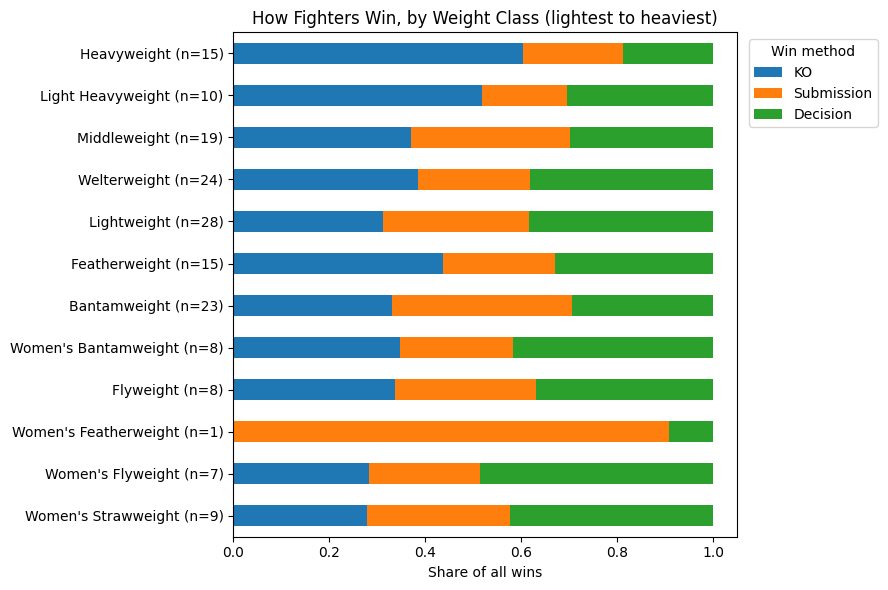

In [10]:
# order weight classes from lightest to heaviest
order = df.groupby("weight_class")["weight_lbs"].median().sort_values().index

# add up every win in each weight class by method, then turn into shares
totals = df.groupby("weight_class")[["ko_wins", "sub_wins", "decision_wins"]].sum().loc[order]
shares = totals.div(totals.sum(axis=1), axis=0)
shares.columns = ["KO", "Submission", "Decision"]

ax = shares.plot(kind="barh", stacked=True, figsize=(9, 6))

counts = df["weight_class"].value_counts()
ax.set_yticks(range(len(order)), [f"{wc} (n={counts[wc]})" for wc in order])
ax.set_xlabel("Share of all wins")
ax.set_ylabel("")
ax.set_title("How Fighters Win, by Weight Class (lightest to heaviest)")
ax.legend(title="Win method", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**What it shows:** Knockouts make up a much bigger share of wins in the heaviest divisions. About 60% of wins at heavyweight and just over half at light heavyweight come by KO, compared with roughly 30–45% in the lighter men’s divisions. The women’s divisions have the lowest KO shares (around 28–35%) and the largest decision shares (often 40–50%). Submission shares vary between divisions (roughly 20–38%) without a clear pattern by weight. Overall, this supports the idea that bigger fighters are more likely to win by knockout, which suggests a fighter’s body may relate to how they win even though it barely relates to how often they win. Several classes have only a few fighters, so their bars are less reliable. Women’s Featherweight has just one fighter, so its bar reflects a single fighter’s record and should be ignored.

## Part 4: Functions for Checking a Machine Learning Model

Our two questions need two different kinds of model:
* **Question 1:** Do physical traits give an edge? This predicts `win_pct`, the win percentage, which is a number, so it needs a **regression** model.
* **Question 2:** Does a fighter's body shape how they win? This predicts `win_style` (KO, submission, or decision), which is a category, so it needs a **classification** model.

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.utils import shuffle

### Function 1: `check_regression_fit()` for Question 1

This function takes the model's predictions and fighters' win percentages and prints:
* R²
* Mean absolute error
* Baseline MAE

This function makes two plots: predicted vs actual, and the residuals which is actual minus predicted.

**Why this is useful:** R² is how much of the variation in win percentage the model explains. MAE is how far off the predictions are on average. Baseline MAE is how far off we'd be if we just guessed the average win percentage for every fighter. MAE by itself can be misleading. Most fighters in our dataset win more than they lose. Win percentages are all clustered together, so a model could get a small MAE just by guessing close to the average without really learning anything. If the model can't beat the baseline, then reach, height, and weight aren't actually helping it predict winning.


The residual plot checks whether a straight line is the right kind of model. If the residuals are randomly scattered around 0, the model is good. Otherwise, the model is missing something.

In [12]:
def check_regression_fit(y_test, y_pred, baseline):
    """Print R^2, MAE, and a baseline MAE, then plot predicted vs actual and the residuals."""
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    baseline_guesses = [baseline] * len(y_test)
    baseline_mae = mean_absolute_error(y_test, baseline_guesses)

    print("R^2:", round(r2, 3))
    print("MAE:", round(mae, 3))
    print("Baseline MAE:", round(baseline_mae, 3))

    if mae < baseline_mae:
        print("The model beats the baseline.")
    else:
        print("The model does NOT beat the baseline, so the features aren't helping.")

    residuals = y_test - y_pred

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].scatter(y_test, y_pred)
    axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
    axes[0].set_xlabel("actual value")
    axes[0].set_ylabel("predicted value")
    axes[0].set_title("Predicted vs. actual")
    axes[1].scatter(y_pred, residuals)
    axes[1].axhline(0, color="red")
    axes[1].set_xlabel("predicted value")
    axes[1].set_ylabel("residual (actual - predicted)")
    axes[1].set_title("Residuals")

    plt.tight_layout()
    plt.show()

### Function 2: `check_classifier()` for Question 2

The function prints the model’s accuracy, two baselines (always guessing the most common win style, and random guessing), the percent of correctness for each win style, and a confusion matrix.

**Why this is useful:**

1. Unbalanced classes: A lot of the fighters of our data are KO fighters. So always guessing “KO” beats random guessing. The model has to beat this baseline.
2. Ignored classes: Checking each style separately catches a model that never predicts one win style.

In [13]:
def check_classifier(y_test, y_pred, classes):
    """Print accuracy vs. two baselines, the percent correct for each class, and a confusion matrix."""
    y_test = list(y_test)
    y_pred = list(y_pred)

    correct = 0
    for i in range(len(y_test)):
        if y_test[i] == y_pred[i]:
            correct += 1
    accuracy = correct / len(y_test)

    most_common = pd.Series(y_test).value_counts().idxmax()
    majority_baseline = y_test.count(most_common) / len(y_test)

    random_baseline = 1 / len(classes)

    print("Accuracy:", round(accuracy * 100, 1), "%")
    print("Majority baseline (always guessing " + most_common + "):", round(majority_baseline * 100, 1), "%")
    print("Random guess baseline:", round(random_baseline * 100, 1), "%")

    if accuracy > majority_baseline:
        print("The model beats always guessing " + most_common + ".")
    else:
        print("The model does NOT beat always guessing " + most_common + ".")

    print()
    print("Percent correct for each win style:")
    for c in classes:
        total = y_test.count(c)
        right = 0
        for i in range(len(y_test)):
            if y_test[i] == c and y_pred[i] == c:
                right += 1
        if total == 0:
            print(" ", c, ": no fighters with this win style in the test set")
        else:
            print(" ", c, ":", round(right / total * 100, 1), "% (", right, "of", total, ")")
            if right == 0:
                print("    warning: the model never gets", c, "right")

    print()
    print(pd.crosstab(pd.Series(y_test, name="actual"), pd.Series(y_pred, name="predicted")))

### Function 3: `check_stability()` for Both Questions

This function uses k-fold cross validation to test the model on the data. Then it prints each fold’s training score, test score, their average, and standard deviation.

**Why this is useful:**

One train/test split can be lucky or unlucky. A big standard deviation means no single score can be trusted. A training score much higher than the test scores means the model is memorizing fighters. If the training score is also low, the features may simply not be related to the target.

In [14]:
def check_stability(model, X, y, k=5):
    """Use k-fold cross validation to check if the score is stable and if the model is overfitting."""
    # shuffle first since the data is sorted by weight class
    X, y = shuffle(X, y, random_state=3000)

    test_scores = cross_val_score(model, X, y, cv=k)

    model.fit(X, y)
    train_score = model.score(X, y)

    print("Test score for each fold:", test_scores.round(3))
    print("Average test score:", round(test_scores.mean(), 3))
    print("Standard deviation:", round(test_scores.std(), 3))
    print("Training score:", round(train_score, 3))

    if test_scores.std() > 0.1:
        print("The scores change a lot between folds, so one train/test split could be misleading.")
    if train_score - test_scores.mean() > 0.15:
        if train_score < 0.2:
            print("The model doesn't even fit the training data well, so the features might just not be related to the target.")
        else:
            print("The model does a lot better on the training data, so it might be overfitting.")

### Trying out the functions

To show the functions work on our data, we run them on two simple first-try models that use only physical traits. These are not our final models (choosing and tuning models comes in the next phase); they just show what each check reports.

R^2: 0.018
MAE: 0.076
Baseline MAE: 0.078
The model beats the baseline.


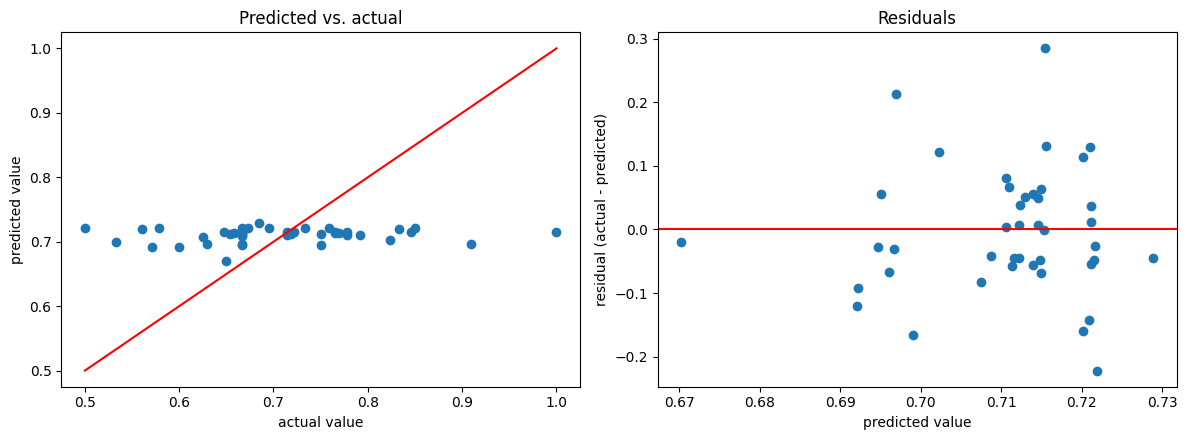

Test score for each fold: [-0.011 -0.041 -0.054 -0.011 -0.025]
Average test score: -0.028
Standard deviation: 0.017
Training score: 0.021


In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier

features = ["height_in", "reach_in", "reach_vs_class", "weight_lbs"]
X = df[features]

# Question 1: regression on win %
y_reg = df["win_pct"]
X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.25, random_state=3000)
reg = LinearRegression().fit(X_train, y_train)
check_regression_fit(y_test, reg.predict(X_test), baseline=y_train.mean())
check_stability(LinearRegression(), X, y_reg)

In [16]:
# Question 2: classification of win style
y_cls = df["win_style"]
X_train, X_test, y_train, y_test = train_test_split(X, y_cls, test_size=0.25, random_state=3000)
clf = DecisionTreeClassifier(max_depth=3, random_state=3000).fit(X_train, y_train)
check_classifier(y_test, clf.predict(X_test), classes=["KO", "Submission", "Decision"])
print()
check_stability(DecisionTreeClassifier(max_depth=3, random_state=3000), X, y_cls)

Accuracy: 57.1 %
Majority baseline (always guessing KO): 54.8 %
Random guess baseline: 33.3 %
The model beats always guessing KO.

Percent correct for each win style:
  KO : 91.3 % ( 21 of 23 )
  Submission : 14.3 % ( 1 of 7 )
  Decision : 16.7 % ( 2 of 12 )

predicted   Decision  KO  Submission
actual                              
Decision           2  10           0
KO                 2  21           0
Submission         0   6           1

Test score for each fold: [0.529 0.529 0.394 0.515 0.455]
Average test score: 0.484
Standard deviation: 0.053
Training score: 0.521


## Part 5: Ethical Considerations

First, a quick look at who is (and isn't) in our sample, since several of the issues below come from it:

In [17]:
print("Fighters sampled for records:", len(all_records))
print("Fighters with no record data in the API:", missing)
print("Fighters in the final data set:", len(df))
print()
print(df["gender"].value_counts().rename({"M": "Men", "W": "Women"}).to_string())
print()
print(df["stance"].value_counts().to_string())

Fighters sampled for records: 225
Fighters with no record data in the API: 58
Fighters in the final data set: 167

gender
Men      142
Women     25

stance
Orthodox    127
Southpaw     23
Switch       17


Our data comes from the API-Sports MMA API and includes fighters’ names, body measurements, and fight records. Fighters with partial or no measurements were not sampled, which likely leaves out older, retired, or less well-known fighters. Our sample also has very few women fighters, and some stance groups are very small (see the counts above). In addition, the API had no win/loss data for 58 of the 225 fighters we sampled, about a quarter, so they were dropped. If those missing records aren't random (for example, if they are mostly newer or lower-profile fighters), our results could be biased toward fighters the API tracks more closely. Each fighter’s record also includes fights outside the UFC, where the level of competition varies. Because of this, our results could change a lot with a larger or different sample.

Every row in our data is a real athlete who did not agree to be part of this analysis. Even though the data is public, our findings describe broad patterns and shouldn’t be used to judge any individual fighter.

If the UFC, another promotion, or a fighter’s management used our model to decide who to sign or who gets matched against whom, fighters could lose opportunities and income because of body measurements they can’t control. The model could also be unfair to women: since it mostly learns from men, it is likely less accurate for women fighters.

It’s also important to remember that correlation is not causation. Even where we do see a pattern, like knockouts making up more of the wins in heavier divisions, that doesn’t prove size causes knockouts. Other factors, like training, fighting style, or the opponents someone faced, could explain the pattern.

People could use the model’s predictions to justify their sports betting positions, even though a model built on a small sample of body measurements is a very uncertain indicator of who will win. Treating these predictions as reliable could encourage people to gamble money they could lose.

Finally, our second question treats knockouts as a “win style,” but a knockout is a brain injury to the opponent. We should present these results carefully and avoid glamorizing knockout power, since repeated head trauma has serious long-term health effects for fighters.